# Quantos clientes voltam a comprar?

**Resposta curta:** quase ninguém. 97% dos clientes compraram uma única vez e a taxa de recompra é de 3,0% (3,1% em até 180 dias, entre clientes que tiveram tempo de voltar). Cerca de 30% das recompras acontecem em menos de 24 horas, o que sugere pedidos divididos mais do que fidelização: sem eles, a taxa cai para cerca de 2,1%. A nota da primeira compra não muda a chance de voltar (de 2,9% a 3,5%, sem padrão).

**Metodologia**
- Cliente = `customer_unique_id`. O `customer_id` muda a cada pedido (96.478 pedidos e 96.478 `customer_id`, mas 93.358 clientes únicos), então usá-lo daria 0% de recompra.
- Recompra = cliente com 2 ou mais pedidos entregues.
- Como o dataset cobre cerca de 2 anos, quem comprou perto do fim teve pouco tempo para voltar. Por isso calculei também a recompra em até 180 dias, apenas entre os 55.907 clientes que tiveram pelo menos 180 dias de janela.

In [1]:
import sys
from pathlib import Path
raiz_projeto = Path().resolve().parent
if str(raiz_projeto) not in sys.path:
    sys.path.append(str(raiz_projeto))

import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns
from src import config
sns.set_theme(style="whitegrid")


engine = create_engine(config.DATABASE_URL)

In [2]:
query = """
SELECT
    c.customer_unique_id,
    c.customer_id,
    o.order_id,
    o.order_purchase_timestamp::timestamp AS data_compra
FROM orders o
JOIN customers c USING (customer_id)
WHERE o.order_status = 'delivered';
"""

df = pd.read_sql(query, engine)

print(f"{df['order_id'].nunique():,} pedidos")
print(f"{df['customer_id'].nunique():,} customer_id (um por pedido)")
print(f"{df['customer_unique_id'].nunique():,} clientes únicos")

96,478 pedidos
96,478 customer_id (um por pedido)
93,358 clientes únicos


In [3]:
pedidos_por_cliente = df.groupby("customer_unique_id")["order_id"].nunique()

dist = pedidos_por_cliente.clip(upper=4).value_counts().sort_index()
dist.index = ["1 pedido", "2 pedidos", "3 pedidos", "4+ pedidos"]

resumo = pd.DataFrame({
    "clientes": dist,
    "pct": (dist / dist.sum() * 100).round(1),
})
print(resumo)

taxa_geral = (pedidos_por_cliente >= 2).mean() * 100
print(f"\nTaxa de recompra geral: {taxa_geral:.1f}%")

            clientes   pct
1 pedido       90557  97.0
2 pedidos       2573   2.8
3 pedidos        181   0.2
4+ pedidos        47   0.1

Taxa de recompra geral: 3.0%


### Quantos voltam
90.557 clientes (97,0%) compraram uma vez; 2.573 (2,8%) compraram duas; 181 (0,2%) três; e 47 (0,1%) quatro ou mais. A taxa de recompra é de 3,0%. Na janela de 180 dias a taxa é de 3,1%, praticamente igual, então o curto período do dataset não distorce muito o resultado.


In [4]:
df = df.sort_values(["customer_unique_id", "data_compra"])
df["n_compra"] = df.groupby("customer_unique_id").cumcount() + 1

primeira = df[df["n_compra"] == 1].set_index("customer_unique_id")["data_compra"]
segunda  = df[df["n_compra"] == 2].set_index("customer_unique_id")["data_compra"]

dias_ate_2a = (segunda - primeira.loc[segunda.index]).dt.days

faixas = pd.cut(
    dias_ate_2a,
    bins=[-1, 0, 30, 90, 180, float("inf")],
    labels=["Menos de 24h", "1-30 dias", "31-90 dias", "91-180 dias", "181+ dias"],
)
tempo = faixas.value_counts().sort_index()
pd.DataFrame({"clientes": tempo, "pct": (tempo / tempo.sum() * 100).round(1)})

,clientes,pct
data_compra,,
Menos de 24h,853,30.5
1-30 dias,570,20.3
31-90 dias,489,17.5
91-180 dias,410,14.6
181+ dias,479,17.1


In [5]:
fim = df["data_compra"].max()

# só clientes que tiveram pelo menos 180 dias para voltar
elegiveis = primeira[primeira <= fim - pd.Timedelta(days=180)]

dias_elegiveis = (segunda.reindex(elegiveis.index) - elegiveis).dt.days
voltou = dias_elegiveis.le(180)   # NaN (nunca voltou) vira False

taxa_180 = voltou.mean() * 100
print(f"{len(elegiveis):,} clientes elegíveis")
print(f"Taxa de recompra em até 180 dias: {taxa_180:.1f}%")

55,907 clientes elegíveis
Taxa de recompra em até 180 dias: 3.1%


In [6]:
query_notas = """
SELECT order_id, AVG(review_score) AS review_score
FROM order_reviews
GROUP BY order_id;
"""
notas = pd.read_sql(query_notas, engine)

primeiras = (
    df[df["n_compra"] == 1][["customer_unique_id", "order_id"]]
      .merge(notas, on="order_id")
      .set_index("customer_unique_id")
)

base = primeiras.loc[primeiras.index.intersection(elegiveis.index)].copy()
base["voltou"] = voltou.reindex(base.index)
base["nota"] = base["review_score"].round().astype(int)

por_nota = base.groupby("nota")["voltou"].agg(clientes="count", taxa_recompra="mean")
por_nota["taxa_recompra"] = (por_nota["taxa_recompra"] * 100).round(1)
por_nota

,clientes,taxa_recompra
nota,,
1,5559,3.0
2,1799,3.5
3,4849,3.2
4,11166,2.9
5,32117,3.2


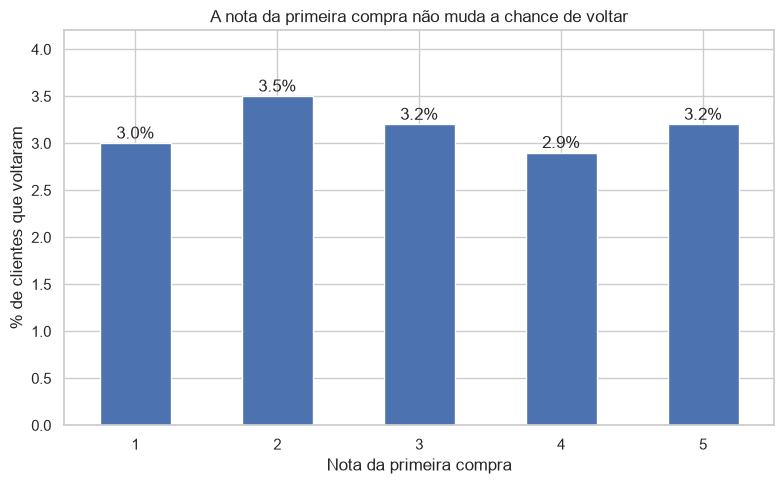

In [ ]:
ax = por_nota["taxa_recompra"].plot(kind="bar", figsize=(8, 5), color="#4C72B0")
ax.set_title("A nota da primeira compra não muda a chance de voltar")
ax.set_xlabel("Nota da primeira compra")
ax.set_ylabel("% de clientes que voltaram")
plt.xticks(rotation=0)

for i, v in enumerate(por_nota["taxa_recompra"]):
    ax.text(i, v + 0.05, f"{v:.1f}%", ha="center")

ax.set_ylim(0, por_nota["taxa_recompra"].max() * 1.2)
plt.tight_layout()
plt.savefig("../reports/figures/04_tempo_ate_segunda_compra.png", dpi=150, bbox_inches="tight")
plt.show()

### Quando voltam
Dos 2.801 clientes que recompraram, 30,5% fizeram a segunda compra em menos de 24 horas e 20,3% entre 1 e 30 dias, de modo que metade das recompras (50,8%) acontece no primeiro mês. Outros 17,5% voltam entre 31 e 90 dias, 14,6% entre 91 e 180 dias e 17,1% depois de 180 dias.

As compras feitas em menos de 24 horas provavelmente são pedidos divididos (o cliente fechou o carrinho em dois pedidos), e não fidelização. Excluindo-as, a taxa de recompra cai de 3,0% para cerca de 2,1% (1.948 de 93.358 clientes).

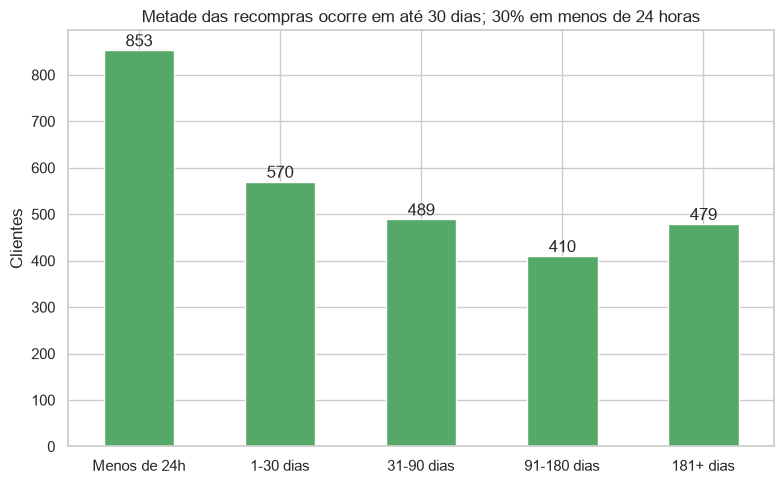

In [ ]:
ax = tempo.plot(kind="bar", figsize=(8, 5), color="#55A868")
ax.set_title("Metade das recompras ocorre em até 30 dias; 30% em menos de 24 horas")
ax.set_xlabel("")
ax.set_ylabel("Clientes")
plt.xticks(rotation=0)

for i, v in enumerate(tempo):
    ax.text(i, v + tempo.max() * 0.01, f"{v:,}".replace(",", "."), ha="center")

plt.tight_layout()
plt.savefig("../reports/figures/04_recompra_por_nota", dpi=150, bbox_inches="tight")
plt.show()

### A nota da primeira compra influencia a volta?
Entre os clientes elegíveis para a janela de 180 dias, a taxa de recompra fica entre 2,9% e 3,5% em todas as notas, sem tendência: clientes que deram 1 estrela voltam (3,0%) tanto quanto os que deram 5 (3,2%). A nota 2 tem a taxa mais alta (3,5%), mas com apenas 1.799 clientes, o que a torna instável.

Ou seja, pelos dados a satisfação medida pela avaliação não explica quem volta. Cerca de 400 clientes elegíveis ficaram de fora desta parte por não terem avaliação.

## Insight e ação
A recompra é um ponto fraco estrutural: 97% dos clientes compram uma única vez, e cerca de um terço das "recompras" são pedidos quase simultâneos. Como a nota da primeira compra não influencia a volta, melhorar a satisfação sozinha (por exemplo, reduzindo atrasos, como mostra o notebook 01) tende a melhorar as avaliações, mas os dados não indicam que isso, por si só, traga o cliente de volta.

A janela mais promissora é o primeiro mês, que concentra metade das recompras.

**Ações possíveis (a testar, não comprovadas):**
- Campanha de reengajamento (e-mail ou cupom) nos primeiros 30 dias após a entrega.
- Incentivo na segunda compra, como frete reduzido ou grátis, já que o frete pesa de 17% a 36% do valor dos produtos (notebook 03).
- Estimular o pedido combinado, para que a divisão de carrinho não se perca em dois fretes.
- Segmentar clientes (por exemplo, com RFM) para identificar quem tem mais chance de voltar.

Hipóteses para a baixa recompra, que os dados não permitem testar: muitas compras são ocasionais (móveis, utilidades), a plataforma não tem programa de fidelidade, e o cliente pode associar a experiência ao vendedor e não à plataforma.

## Limitações
- O `customer_unique_id` depende de como o Olist anonimizou os clientes: quem mudou dados cadastrais pode aparecer como pessoas diferentes.
- O dataset cobre cerca de 2 anos de um marketplace em crescimento e só registra compras na própria plataforma.
- A ausência de relação entre nota e recompra não prova que satisfação não importa: a nota mede apenas a primeira compra e muitos clientes não avaliam.
- Os dados mostram associação, não causalidade.